In [1]:
import os
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import sys
import numpy as np
import random
sys.path.append('..')
from models.cifar10_autoencoder import CIFAR10Autoencoder
from trainers.autoencoder_trainer import AutoencoderTrainer
from models.cifar10_classifier import CIFAR10Classifier
from trainers.classifier_trainer import ClassifierTrainer

In [2]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)  

In [3]:
data_path = os.path.join("..", "data")
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=15),
    transforms.RandomAffine(0, translate=(0.1, 0.1)),
    transforms.ToTensor()
])
val_transform = transforms.ToTensor()
test_transform = transforms.ToTensor()

Files already downloaded and verified
Files already downloaded and verified
Epoch [1] - Train Loss: 0.1042, Val Loss: 0.0805, Test Loss: 0.0805
              Train L1: 0.1042,  Val L1: 0.0805, Test L1: 0.0805
Epoch [2] - Train Loss: 0.0684, Val Loss: 0.0681, Test Loss: 0.0681
              Train L1: 0.0684,  Val L1: 0.0681, Test L1: 0.0681
Epoch [3] - Train Loss: 0.0607, Val Loss: 0.0614, Test Loss: 0.0613
              Train L1: 0.0607,  Val L1: 0.0614, Test L1: 0.0613
Epoch [4] - Train Loss: 0.0571, Val Loss: 0.0588, Test Loss: 0.0588
              Train L1: 0.0571,  Val L1: 0.0588, Test L1: 0.0588
Epoch [5] - Train Loss: 0.0548, Val Loss: 0.0551, Test Loss: 0.0550
              Train L1: 0.0548,  Val L1: 0.0551, Test L1: 0.0550
Epoch [6] - Train Loss: 0.0532, Val Loss: 0.0536, Test Loss: 0.0534
              Train L1: 0.0532,  Val L1: 0.0536, Test L1: 0.0534
Epoch [7] - Train Loss: 0.0522, Val Loss: 0.0550, Test Loss: 0.0549
              Train L1: 0.0522,  Val L1: 0.0550, Test L1: 

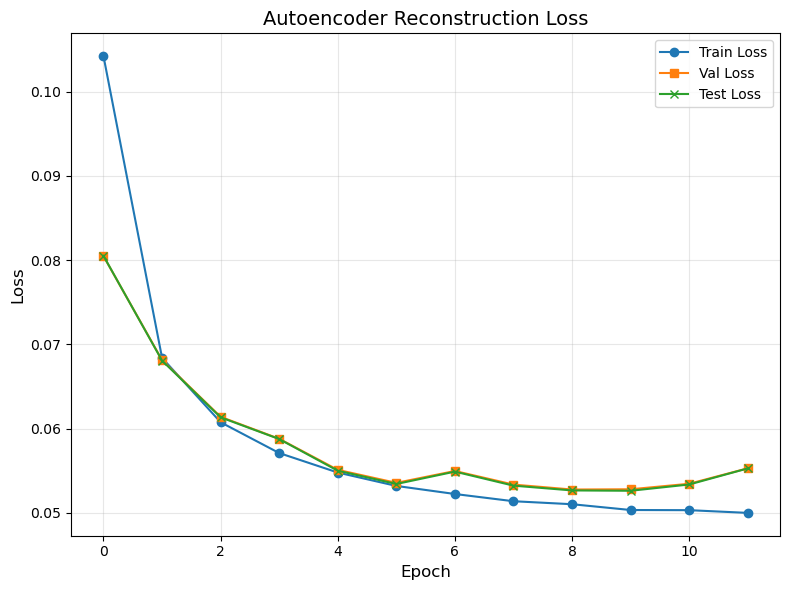

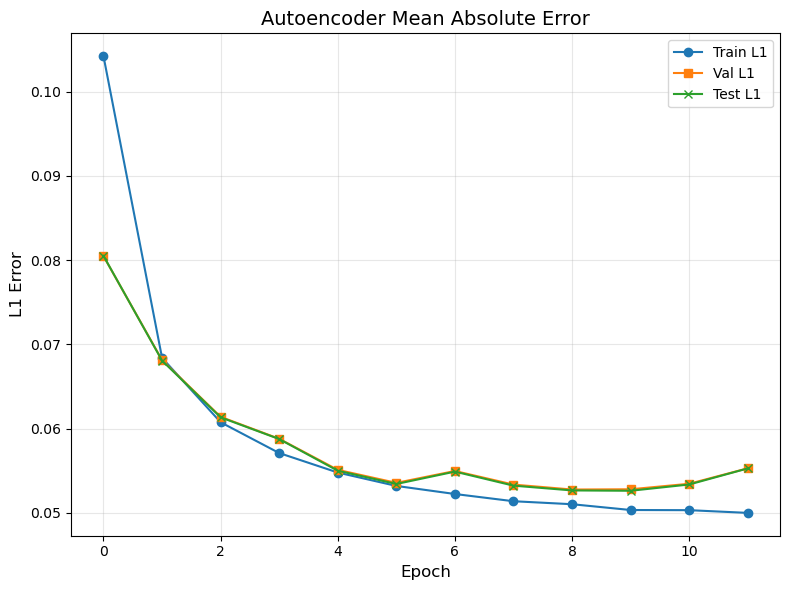

=== Final Autoencoder Metrics ===
Train ReconLoss: 0.0500
Val   ReconLoss: 0.0553
Test  ReconLoss: 0.0553
Train L1: 0.0500
Val   L1: 0.0553
Test  L1: 0.0553


In [10]:
full_train_dataset = datasets.CIFAR10(root=data_path, train=True, download=True)
test_dataset   = datasets.CIFAR10(root=data_path, train=False, download=True)

train_size = int(0.8 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_subset, val_subset = torch.utils.data.random_split(
    full_train_dataset, [train_size, val_size]
)
class TransformedSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

train_dataset = TransformedSubset(train_subset, train_transform)
val_dataset = TransformedSubset(val_subset, val_transform)
test_dataset = TransformedSubset(test_dataset, test_transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

autoencoder_l1_loss = CIFAR10Autoencoder(latent_dim=128)
autoencoder_trainer = AutoencoderTrainer(
model=autoencoder_l1_loss,
train_loader=train_loader,
val_loader=val_loader,
test_loader = test_loader,
scheduler_type='plateau',
criterion=torch.nn.L1Loss(),
device='cuda',
lr=5e-4,
num_epochs=100,
weight_decay=1e-5,
)
autoencoder_trainer.train()
autoencoder_trainer.plot_metrics()

Epoch [1] - TrainAcc: 0.3245, ValAcc: 0.4180, TestAcc: 0.4207 | ValLoss: 1.6424
Epoch [2] - TrainAcc: 0.3881, ValAcc: 0.4511, TestAcc: 0.4526 | ValLoss: 1.5348
Epoch [3] - TrainAcc: 0.4101, ValAcc: 0.4646, TestAcc: 0.4691 | ValLoss: 1.4768
Epoch [4] - TrainAcc: 0.4253, ValAcc: 0.4818, TestAcc: 0.4870 | ValLoss: 1.4392
Epoch [5] - TrainAcc: 0.4359, ValAcc: 0.4856, TestAcc: 0.4877 | ValLoss: 1.4172
Epoch [6] - TrainAcc: 0.4414, ValAcc: 0.4987, TestAcc: 0.5044 | ValLoss: 1.3943
Epoch [7] - TrainAcc: 0.4494, ValAcc: 0.5061, TestAcc: 0.5033 | ValLoss: 1.3812
Epoch [8] - TrainAcc: 0.4546, ValAcc: 0.5081, TestAcc: 0.5087 | ValLoss: 1.3601
Epoch [9] - TrainAcc: 0.4587, ValAcc: 0.5133, TestAcc: 0.5155 | ValLoss: 1.3524
Epoch [10] - TrainAcc: 0.4650, ValAcc: 0.5199, TestAcc: 0.5164 | ValLoss: 1.3331
Epoch [11] - TrainAcc: 0.4681, ValAcc: 0.5227, TestAcc: 0.5244 | ValLoss: 1.3295
Epoch [12] - TrainAcc: 0.4729, ValAcc: 0.5308, TestAcc: 0.5222 | ValLoss: 1.3142
Epoch [13] - TrainAcc: 0.4727, ValAcc

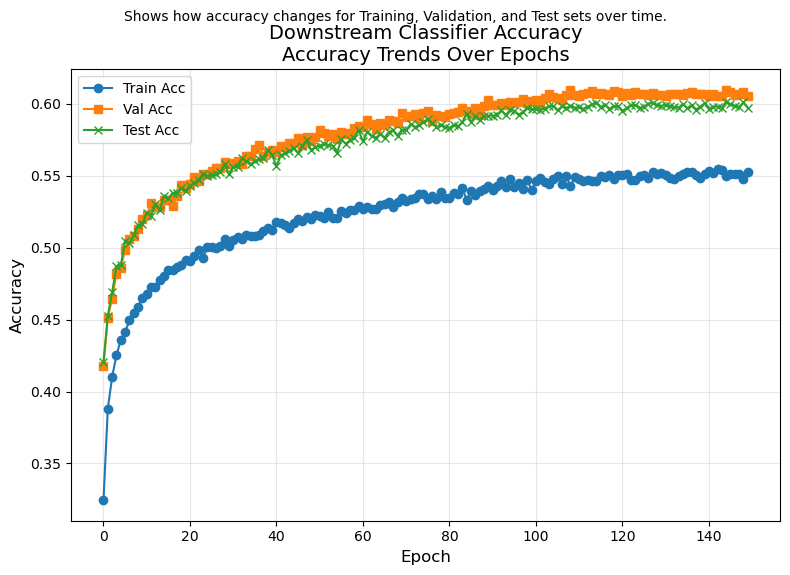

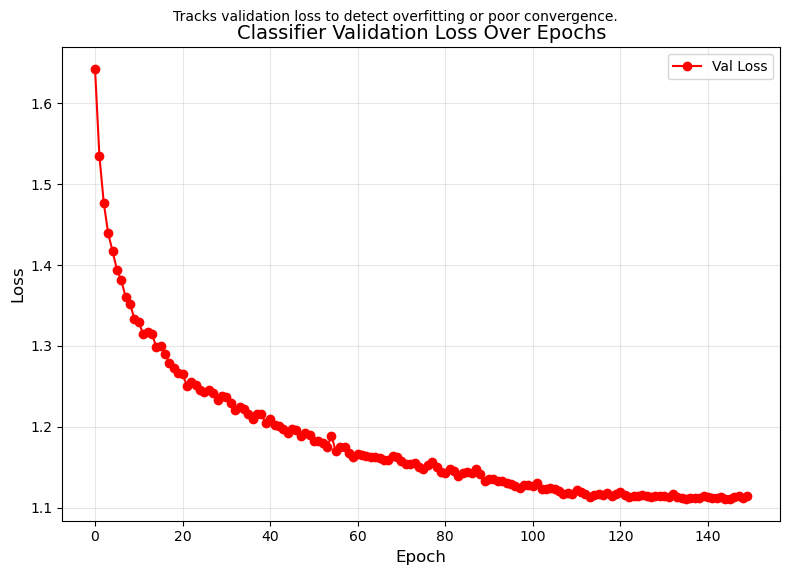

=== Final Classifier Metrics ===
Val Loss: 1.1142
Train Acc: 55.27%
Val   Acc: 60.54%
Test  Acc: 59.71%


In [12]:

classifier2 = CIFAR10Classifier(latent_dim=128, num_classes=10)
classifier_trainer2 = ClassifierTrainer(
encoder=autoencoder_l1_loss.encoder,
classifier=classifier2,
train_loader=train_loader,
val_loader=val_loader,
test_loader =test_loader,
lr =7e-4 ,
weight_decay=1e-4,
scheduler_type='cosine',
num_epochs=150,
patience=10
)
classifier_trainer2.train() 
print("Autoencoder training done.")
classifier_trainer2.plot_metrics()

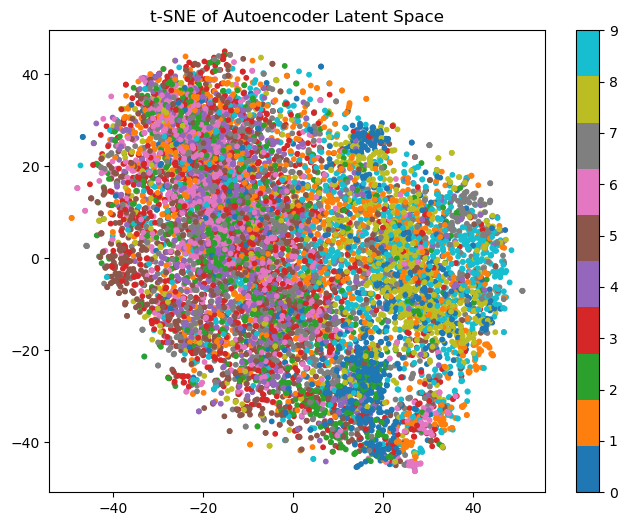

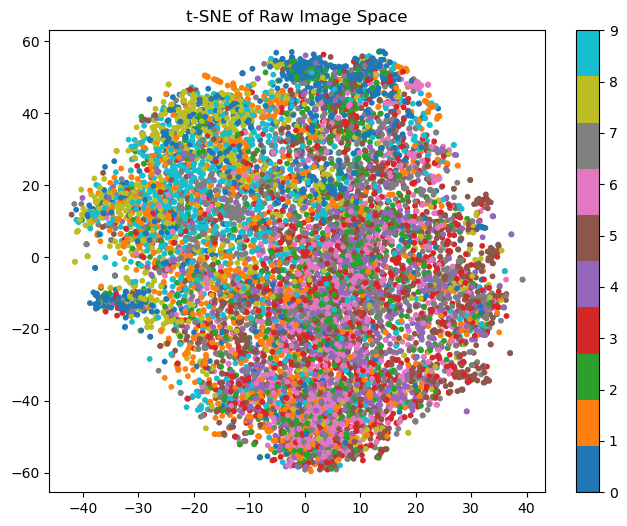

In [14]:
from utils import plot_tsne_autoencoder
plot_tsne_autoencoder(autoencoder_l1_loss, test_loader, device='cuda')

